# Week 2: Length-scale sensitivity across all functions

Measure how the maximized Gaussian-process log marginal likelihood changes as the maximum kernel length scale varies for Functions 1 through 8. Each panel shows all five kernels. Matérn 3/2, Matérn 5/2, and RBF are the benchmark kernels; Rational Quadratic and Exp-Sine-Squared are shown for comparison only and do not inform decisions. Training RMSE is retained as a secondary diagnostic.

This is an in-sample model-fit sensitivity analysis. The caps in `recommended_length_caps` are fixed values entered in the notebook, not computed by it. Likelihood is not a predictive validation result; use held-out validation to compare predictive performance.

## Method

For each function and kernel, refit a Gaussian process using the original seven maximum length-scale caps from `0.01` to `10`. Functions 1, 2, 3, 5, 6, 7, and 8 also get additional caps, up to `31.62` or `100`, as set in `LENGTH_CAPS_BY_FUNCTION`. Each kernel's length scale uses the cap being tested, with a fixed lower bound of `1e-3`; Exp-Sine-Squared periodicity uses fixed bounds of `1e-2` to `1e2`. Target normalization, optimizer restarts, and random seed are read from the project `config.yaml` settings.

Matérn 3/2, Matérn 5/2, and RBF are the benchmark kernels (`CAP_SELECTION_KERNELS`). Only these three inform the selected length-scale caps. Rational Quadratic and Exp-Sine-Squared are included for comparison only and do not inform any decision.

The main plot shows maximized log marginal likelihood (LML), the objective optimized during fitting. `Delta LML` is the change from the immediately preceding cap for the same function and kernel; positive values indicate improvement. Each function has its own y-scale because likelihood values depend on the number of observations. Training RMSE remains a secondary in-sample diagnostic, and convergence warnings are counted per fit across all fitted parameters.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.exceptions import ConvergenceWarning
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (
    ConstantKernel,
    ExpSineSquared,
    Matern,
    RBF,
    RationalQuadratic,
    WhiteKernel,
)

from bayesian_bbo import CONFIG, FUNCTION_SPECS, load_observations

FUNCTION_IDS = tuple(FUNCTION_SPECS)
CAP_SELECTION_KERNELS = ("Matérn 3/2", "Matérn 5/2", "RBF")
LENGTH_CAPS_BY_FUNCTION = {
    1: np.concatenate((np.logspace(-2, 1, 7), np.logspace(1, 2, 3)[1:])),
    2: np.concatenate((np.logspace(-2, 1, 7), np.logspace(1, 2, 3)[1:])),
    3: np.concatenate((np.logspace(-2, 1, 7), np.logspace(1, 1.5, 2)[1:])),
    4: np.logspace(-2, 1, 7),
    5: np.concatenate((np.logspace(-2, 1, 7), np.logspace(1, 2, 5)[1:])),
    6: np.concatenate((np.logspace(-2, 1, 7), np.logspace(1, 2, 3)[1:])),
    7: np.concatenate((np.logspace(-2, 1, 7), np.logspace(1, 2, 3)[1:])),
    8: np.concatenate((np.logspace(-2, 1, 7), np.logspace(1, 2, 5)[1:])),
}
plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
WEEK = 2  # read observations recorded up to and including this week
data_candidates = [Path("../../data"), Path("data"), Path("../data")]
data_root = next(
    (path.resolve() for path in data_candidates if (path / "function_1").is_dir()),
    None,
)
if data_root is None:
    raise FileNotFoundError("Could not find the data directory from the notebook working directory.")

observations_by_function = {
    function_id: load_observations(data_root, function_id, up_to_week=WEEK)
    for function_id in FUNCTION_IDS
}

function_summary = pd.DataFrame(
    [
        {
            "function_id": function_id,
            "observations": len(observations.inputs),
            "dimension": observations.dimension,
            "input_min": float(observations.inputs.min()),
            "input_max": float(observations.inputs.max()),
        }
        for function_id, observations in observations_by_function.items()
    ]
)
print(f"Data root: {data_root}")
function_summary

Data root: /home/pabloncho/repositories/bayesian-bbo/data


,function_id,observations,dimension,input_min,input_max
0,1,11,2,0.078723,0.883890
1,2,11,2,0.028698,0.932779
2,3,16,3,0.046809,0.990882
3,4,31,4,0.006250,0.999483
4,5,21,4,0.038193,0.957644
5,6,21,5,0.004911,0.978806
6,7,31,6,0.003635,0.998655
7,8,41,8,0.003419,0.998885


In [3]:
def make_kernel_candidates(dimension, length_upper_bound):
    length_bounds = (1e-3, length_upper_bound)

    def amplitude():
        return ConstantKernel(1.0, (1e-3, 1e3))

    def noise():
        return WhiteKernel(1e-5, (1e-8, 1e1))

    return {
        "Matérn 3/2": lambda: (
            amplitude()
            * Matern(length_scale=np.ones(dimension), length_scale_bounds=length_bounds, nu=1.5)
            + noise()
        ),
        "Matérn 5/2": lambda: (
            amplitude()
            * Matern(length_scale=np.ones(dimension), length_scale_bounds=length_bounds, nu=2.5)
            + noise()
        ),
        "RBF": lambda: (
            amplitude()
            * RBF(length_scale=np.ones(dimension), length_scale_bounds=length_bounds)
            + noise()
        ),
        "Rational Quadratic": lambda: (
            amplitude()
            * RationalQuadratic(length_scale=1.0, length_scale_bounds=length_bounds, alpha=1.0)
            + noise()
        ),
        "Exp-Sine-Squared": lambda: (
            amplitude()
            * ExpSineSquared(
                length_scale=1.0,
                periodicity=10,
                length_scale_bounds=length_bounds,
                periodicity_bounds=(1e-2, 1e2),
            )
            + noise()
        ),
    }

## Run the sensitivity sweep

For each fit, record the maximized log marginal likelihood, training RMSE, and convergence-warning count on the same observations. No validation rows are held out in this analysis.

In [ ]:
sensitivity_records = []

for function_id, observations in observations_by_function.items():
    inputs = observations.inputs
    outputs = observations.outputs
    for upper_bound in LENGTH_CAPS_BY_FUNCTION[function_id]:
        kernel_factories = make_kernel_candidates(inputs.shape[1], float(upper_bound))
        for kernel_name, kernel_factory in kernel_factories.items():
            model = GaussianProcessRegressor(
                kernel=kernel_factory(),
                normalize_y=CONFIG["normalize_y"],
                n_restarts_optimizer=CONFIG["n_restarts_optimizer"],
                random_state=CONFIG["random_state"],
            )
            with warnings.catch_warnings(record=True) as fit_warnings:
                warnings.simplefilter("always", ConvergenceWarning)
                model.fit(inputs, outputs)
            prediction = model.predict(inputs)
            sensitivity_records.append({
                "function_id": function_id,
                "kernel": kernel_name,
                "max_length_scale": float(upper_bound),
                "max_log_marginal_likelihood": float(model.log_marginal_likelihood_value_),
                "training_RMSE": float(np.sqrt(np.mean((outputs - prediction) ** 2))),
                "convergence_warnings": sum(
                    issubclass(warning.category, ConvergenceWarning)
                    for warning in fit_warnings
                ),
            })

length_sensitivity = pd.DataFrame(sensitivity_records).sort_values(
    ["function_id", "kernel", "max_length_scale"]
)
length_sensitivity["delta_log_marginal_likelihood"] = (
    length_sensitivity.groupby(["function_id", "kernel"])["max_log_marginal_likelihood"]
    .diff()
)
length_sensitivity.head()

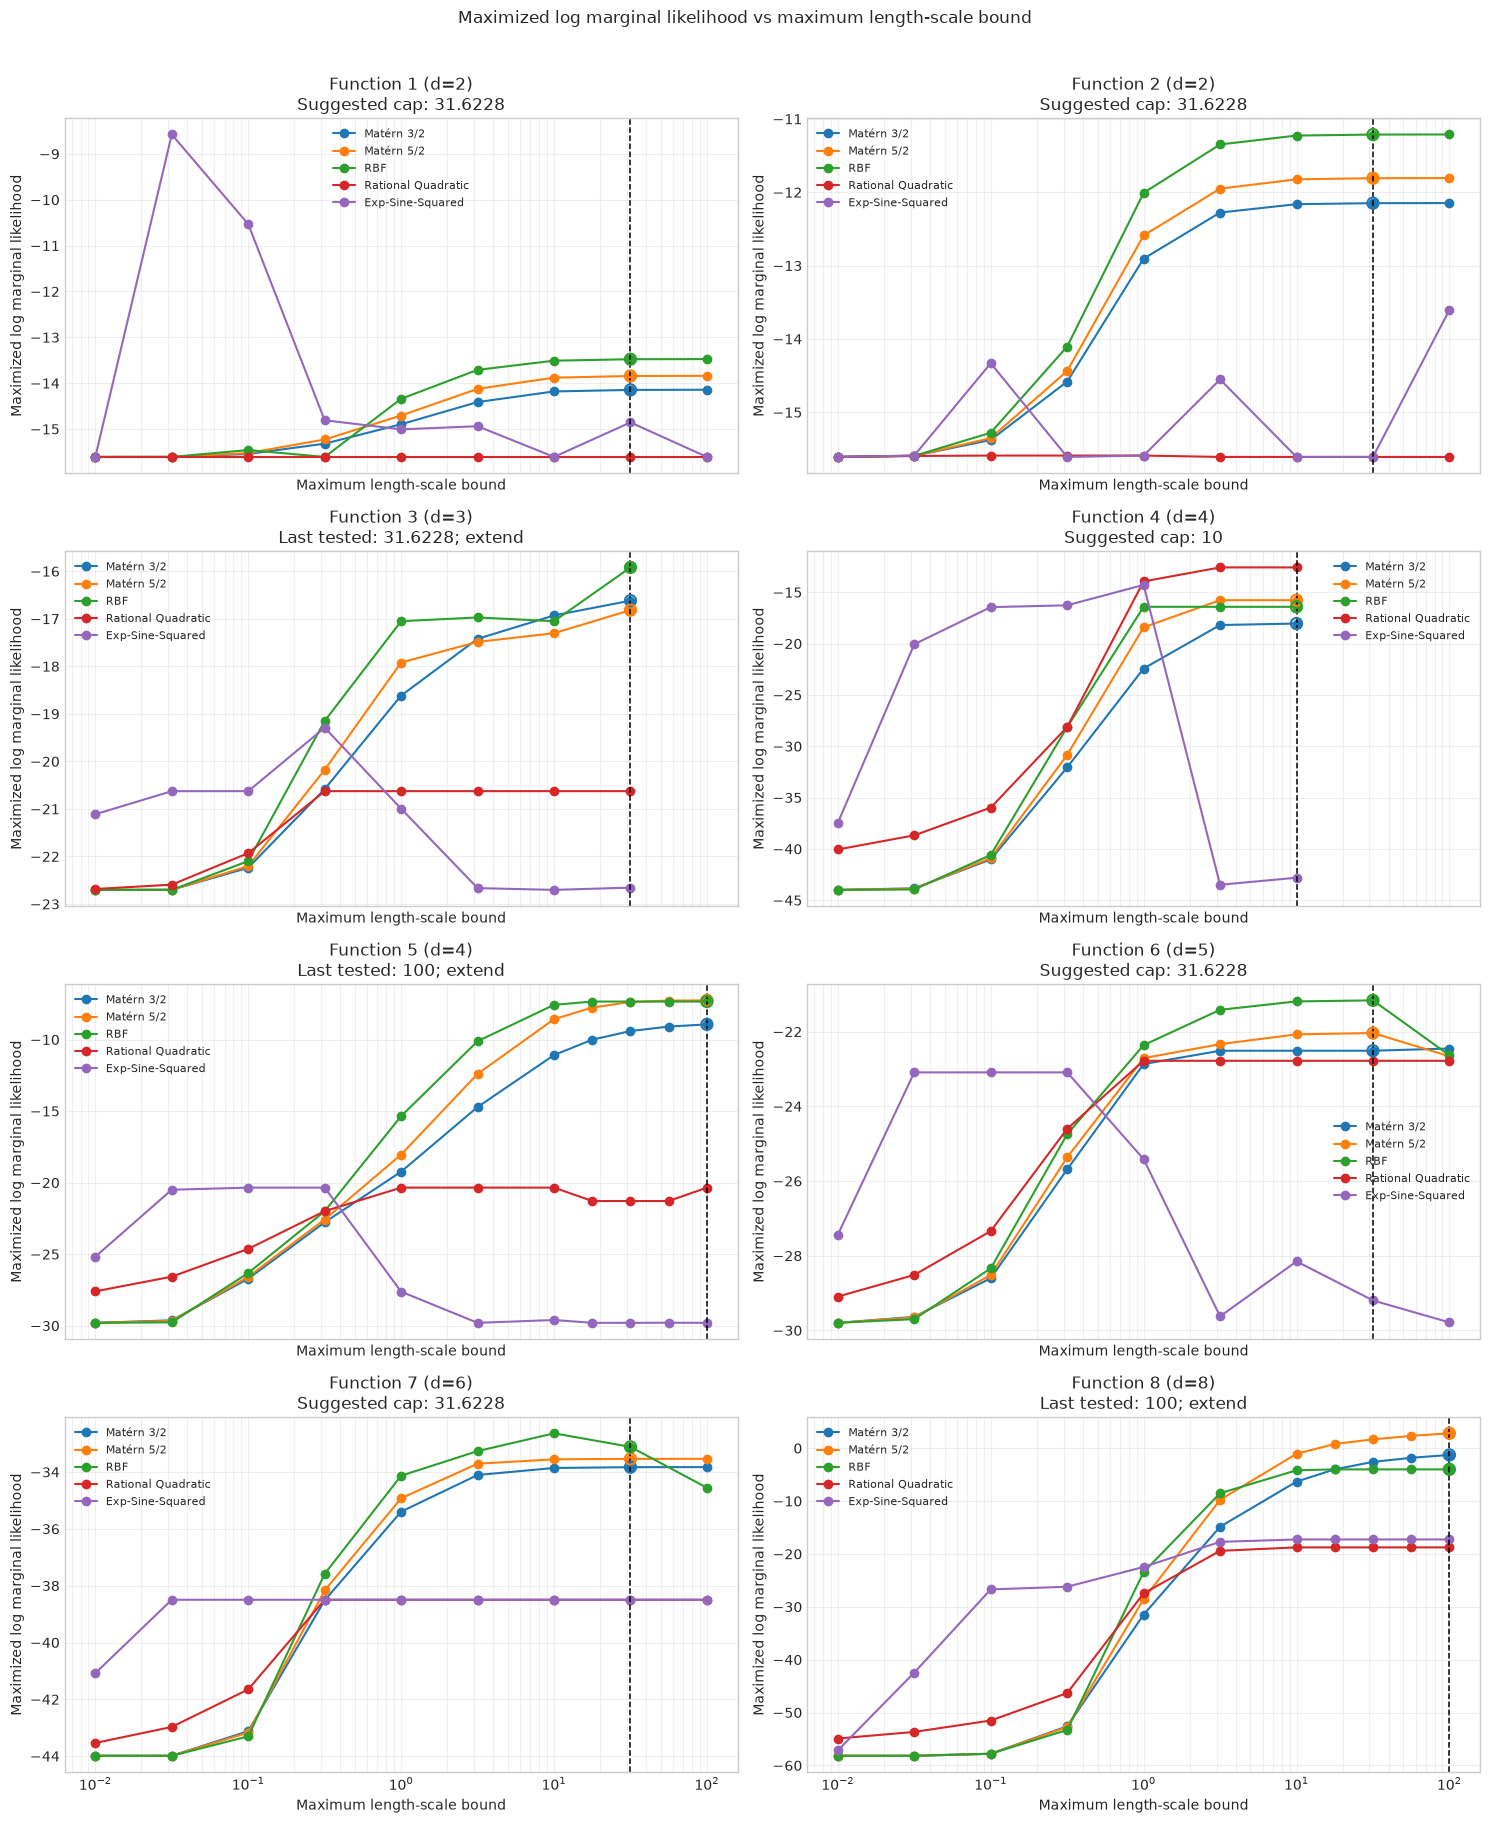

In [ ]:
figure, axes = plt.subplots(4, 2, figsize=(15, 18), sharex=True, sharey=False)
axes = axes.ravel()
maximum_length_cap = max(caps.max() for caps in LENGTH_CAPS_BY_FUNCTION.values())
kernel_names = list(make_kernel_candidates(1, float(maximum_length_cap)))
CAPS_NEEDING_EXTENSION = {3, 5, 8}
recommended_length_caps = {
    1: 31.622776601683793,
    2: 31.622776601683793,
    3: 31.622776601683793,
    4: 10.0,
    5: 100.0,
    6: 31.622776601683793,
    7: 31.622776601683793,
    8: 100.0,
}

for function_id, ax in zip(FUNCTION_IDS, axes):
    function_results = length_sensitivity[length_sensitivity["function_id"] == function_id]
    recommended_cap = recommended_length_caps[function_id]
    for kernel_name in kernel_names:
        kernel_results = function_results[function_results["kernel"] == kernel_name]
        line, = ax.plot(
            kernel_results["max_length_scale"],
            kernel_results["max_log_marginal_likelihood"],
            marker="o",
            label=kernel_name,
        )
        recommended_point = kernel_results[
            np.isclose(kernel_results["max_length_scale"], recommended_cap)
        ]
        if kernel_name in CAP_SELECTION_KERNELS and not recommended_point.empty:
            ax.scatter(
                recommended_point["max_length_scale"],
                recommended_point["max_log_marginal_likelihood"],
                s=65,
                facecolors="none",
                edgecolors=line.get_color(),
                linewidths=1.5,
                zorder=5,
            )
    ax.axvline(recommended_cap, color="black", linestyle="--", linewidth=1.1)
    if function_id in CAPS_NEEDING_EXTENSION:
        cap_label = f"Last tested: {recommended_cap:g}; extend"
    else:
        cap_label = f"Suggested cap: {recommended_cap:g}"
    ax.set_xscale("log")
    ax.set_title(
        f"Function {function_id} (d={observations_by_function[function_id].dimension})\n"
        f"{cap_label}"
    )
    ax.grid(True, which="both", alpha=0.3)
    ax.set_xlabel("Maximum length-scale bound")
    ax.set_ylabel("Maximized log marginal likelihood")
    ax.legend(fontsize=8)
figure.suptitle("Maximized log marginal likelihood vs maximum length-scale bound", y=1.01)
figure.tight_layout()
plt.show()

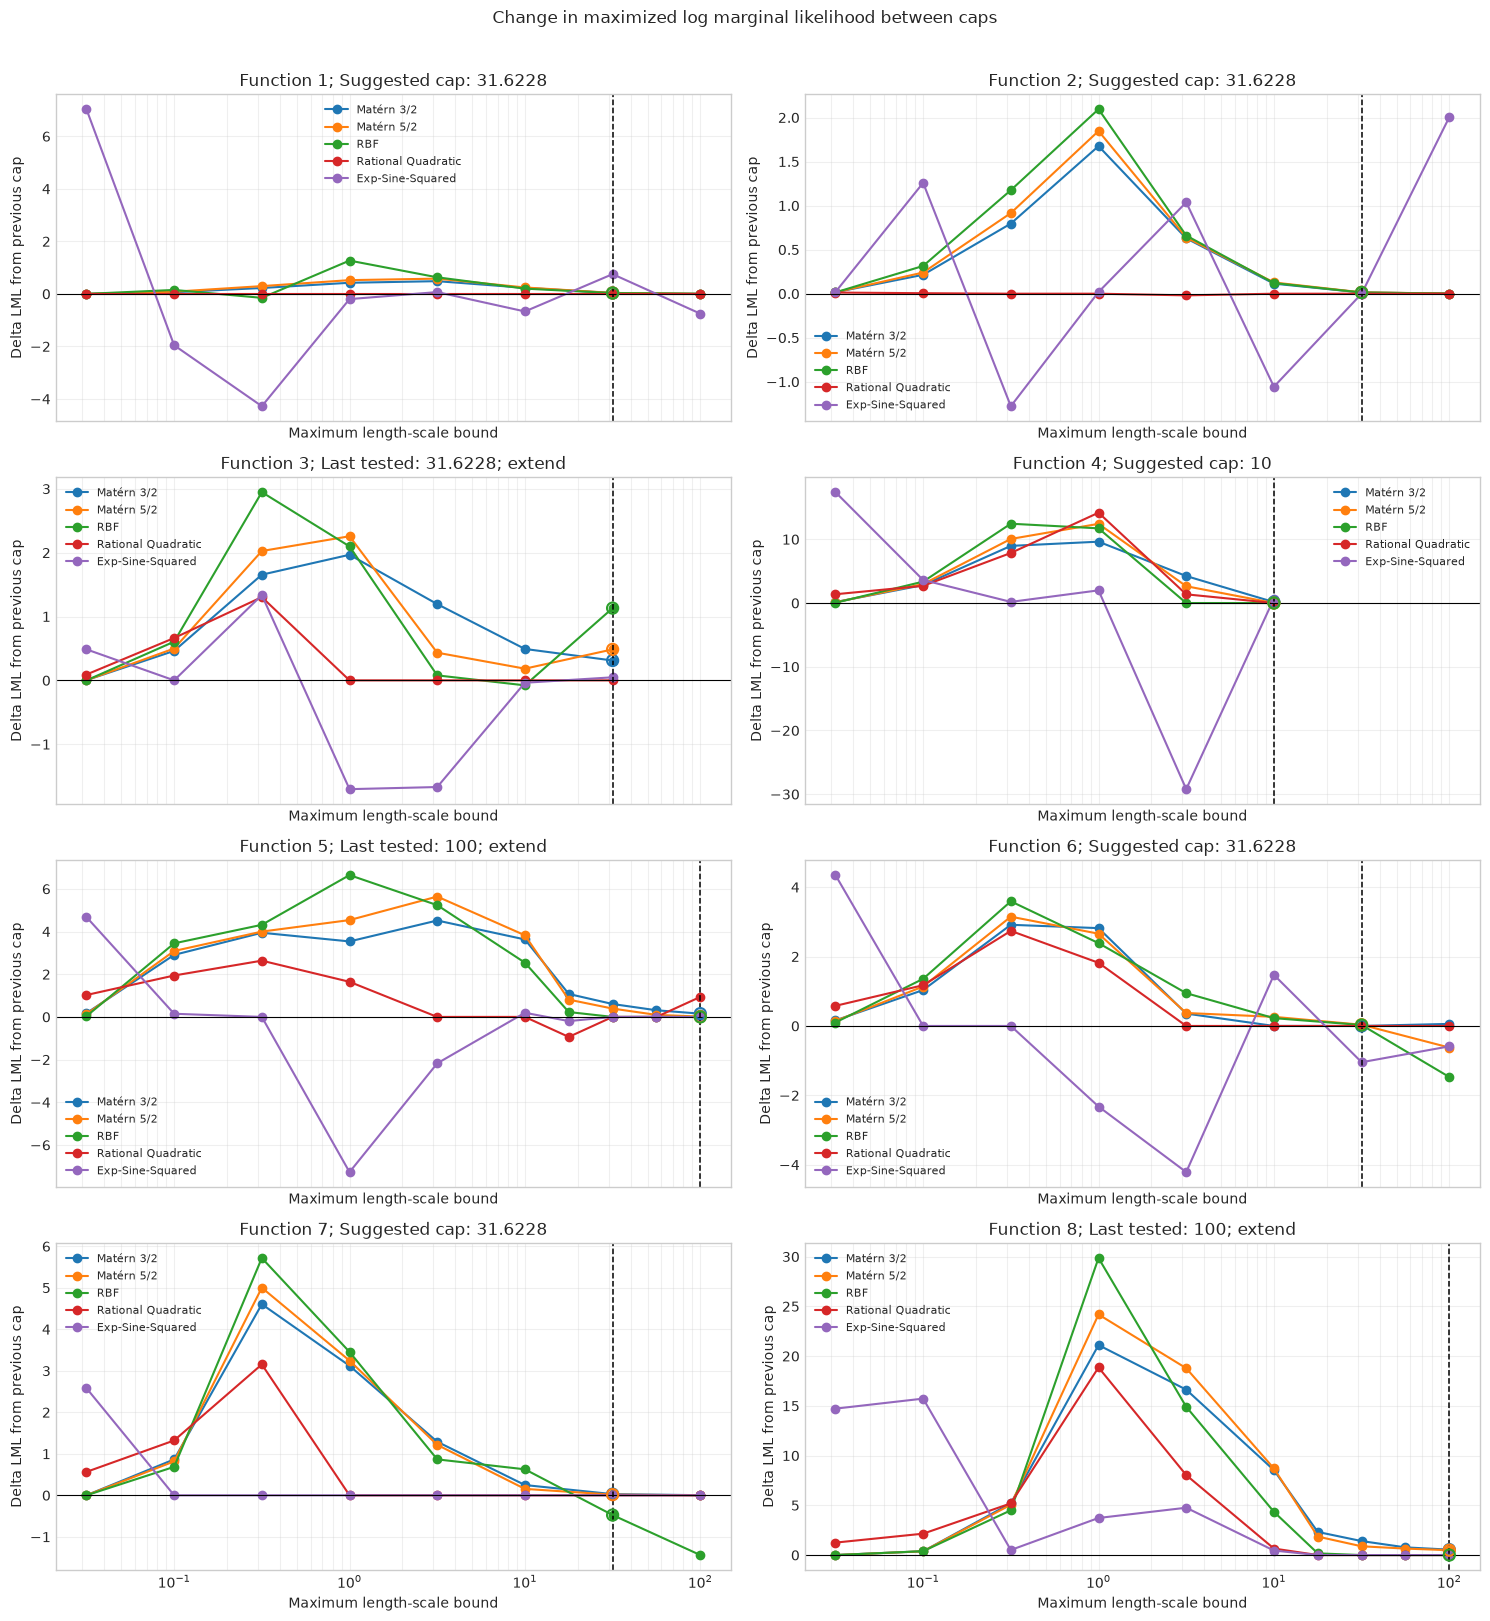

In [ ]:
figure, axes = plt.subplots(4, 2, figsize=(15, 16), sharex=True, sharey=False)
axes = axes.ravel()

for function_id, ax in zip(FUNCTION_IDS, axes):
    function_results = length_sensitivity[length_sensitivity["function_id"] == function_id]
    recommended_cap = recommended_length_caps[function_id]
    for kernel_name in kernel_names:
        kernel_results = function_results[function_results["kernel"] == kernel_name]
        line, = ax.plot(
            kernel_results["max_length_scale"],
            kernel_results["delta_log_marginal_likelihood"],
            marker="o",
            label=kernel_name,
        )
        recommended_point = kernel_results[
            np.isclose(kernel_results["max_length_scale"], recommended_cap)
        ]
        if kernel_name in CAP_SELECTION_KERNELS and not recommended_point.empty:
            ax.scatter(
                recommended_point["max_length_scale"],
                recommended_point["delta_log_marginal_likelihood"],
                s=65,
                facecolors="none",
                edgecolors=line.get_color(),
                linewidths=1.5,
                zorder=5,
            )
    ax.axhline(0.0, color="black", linewidth=0.8)
    ax.axvline(recommended_cap, color="black", linestyle="--", linewidth=1.1)
    if function_id in CAPS_NEEDING_EXTENSION:
        cap_label = f"Last tested: {recommended_cap:g}; extend"
    else:
        cap_label = f"Suggested cap: {recommended_cap:g}"
    ax.set_xscale("log")
    ax.set_title(f"Function {function_id}; {cap_label}")
    ax.grid(True, which="both", alpha=0.3)
    ax.set_xlabel("Maximum length-scale bound")
    ax.set_ylabel("Delta LML from previous cap")
    ax.legend(fontsize=8)
figure.suptitle("Change in maximized log marginal likelihood between caps", y=1.01)
figure.tight_layout()
plt.show()

## Results

Both plots show all five kernel curves. The dashed line marks the selected cap; hollow circles mark that cap for the selection kernels only: Matérn 3/2, Matérn 5/2, and RBF. Rational Quadratic and Exp-Sine-Squared are still fitted and shown, but their results do not affect cap selection. Functions 3, 5, and 8 are marked for extension (`CAPS_NEEDING_EXTENSION`).

The selected caps are `31.62` for Functions 1, 2, 3, 6, and 7, `10` for Function 4, and `100` for Functions 5 and 8. Function 2's Exp-Sine-Squared LML rises by about `2.0` from cap `31.62` to `100`, but that kernel is excluded from cap selection by design. At Function 3's sweep limit, Delta LML remains positive for the three selection kernels, so treat its cap as provisional. The tables still report all five kernels at the selected caps: maximized log marginal likelihood, its change from the preceding cap (`Delta LML`), training RMSE, and convergence-warning counts. Compare likelihoods and deltas within a function, not across functions with different sample counts. Warning counts include all fitted kernel parameters and do not identify which parameter reached a bound.

## Kernel for Notebook 06

Notebook 06 generates its submission candidates with Matérn 3/2, using the selected caps above. That choice follows the held-out cross-validation in Notebook 04, not this in-sample likelihood sweep. Here the likelihood favors RBF on most functions, which conflicts with the cross-validation result. Rational Quadratic and Exp-Sine-Squared do not inform the choice.

In [ ]:
recommended_results = length_sensitivity.assign(
    recommended_cap=length_sensitivity["function_id"].map(recommended_length_caps)
 )
recommended_results = recommended_results[
    np.isclose(recommended_results["max_length_scale"], recommended_results["recommended_cap"])
].copy()
recommended_results["max_length_scale"] = recommended_results["recommended_cap"]
recommended_index = pd.MultiIndex.from_tuples(
    list(recommended_length_caps.items()),
    names=["function_id", "max_length_scale"],
)

likelihood_by_function_and_cap = recommended_results.pivot(
    index=["function_id", "max_length_scale"],
    columns="kernel",
    values="max_log_marginal_likelihood",
).reindex(recommended_index)
delta_likelihood_by_function_and_cap = recommended_results.pivot(
    index=["function_id", "max_length_scale"],
    columns="kernel",
    values="delta_log_marginal_likelihood",
).reindex(recommended_index)
rmse_by_function_and_cap = recommended_results.pivot(
    index=["function_id", "max_length_scale"],
    columns="kernel",
    values="training_RMSE",
).reindex(recommended_index)
warning_counts = recommended_results.pivot(
    index=["function_id", "max_length_scale"],
    columns="kernel",
    values="convergence_warnings",
).reindex(recommended_index)
print("Maximized log marginal likelihood at selected caps")
display(likelihood_by_function_and_cap)
print("Delta log marginal likelihood from previous cap at selected caps")
display(delta_likelihood_by_function_and_cap)
print("Training RMSE at selected caps")
display(rmse_by_function_and_cap)
print("Convergence-warning counts at selected caps")
display(warning_counts)

Maximized log marginal likelihood at selected caps


,kernel,Exp-Sine-Squared,Matérn 3/2,Matérn 5/2,RBF,Rational Quadratic
function_id,max_length_scale,,,,,
1,31.622777,-14.855503,-14.146760,-13.843269,-13.477551,-15.608324
2,31.622777,-15.608324,-12.148725,-11.808366,-11.213481,-15.608323
3,31.622777,-22.655204,-16.618410,-16.817843,-15.919141,-20.626129
4,10.000000,-42.800966,-18.046233,-15.772134,-16.417055,-12.580172
5,100.000000,-29.797709,-8.939841,-7.261247,-7.344686,-20.347646
6,31.622777,-29.198271,-22.511333,-22.037550,-21.162482,-22.780473
7,31.622777,-38.496008,-33.829433,-33.537113,-33.113963,-38.495745
8,100.000000,-17.261896,-1.276315,2.811519,-4.009164,-18.760990


Delta log marginal likelihood from previous cap at selected caps


,kernel,Exp-Sine-Squared,Matérn 3/2,Matérn 5/2,RBF,Rational Quadratic
function_id,max_length_scale,,,,,
1,31.622777,0.751918,0.033352,3.635279e-02,3.178821e-02,0.000000e+00
2,31.622777,0.000000,0.013625,1.504379e-02,1.371714e-02,6.952124e-07
3,31.622777,0.047813,0.310946,4.852356e-01,1.131145e+00,4.955986e-09
4,10.000000,0.690517,0.146083,2.954970e-09,2.137377e-05,-7.460699e-13
5,100.000000,-0.008455,0.153205,1.626345e-02,2.082459e-10,9.373105e-01
6,31.622777,-1.045399,0.000000,3.510478e-02,2.758111e-02,-1.379910e-10
7,31.622777,0.000000,0.028004,1.580165e-02,-4.761917e-01,-2.118143e-06
8,100.000000,0.000000,0.544697,4.903799e-01,1.657202e-08,4.999237e-10


Training RMSE at selected caps


,kernel,Exp-Sine-Squared,Matérn 3/2,Matérn 5/2,RBF,Rational Quadratic
function_id,max_length_scale,,,,,
1,31.622777,4.842044e-05,1.080847e-11,1.082993e-11,1.077004e-11,1.033964e-03
2,31.622777,2.150727e-01,9.702587e-03,1.020070e-02,1.032621e-02,9.707761e-08
3,31.622777,1.707108e-06,4.371034e-07,2.076811e-07,5.367090e-09,5.695951e-08
4,10.000000,1.692082e-04,2.217814e-07,3.621858e-07,4.716592e-07,4.385908e-07
5,100.000000,3.488635e-02,2.099542e-05,2.820005e-05,2.793720e-05,4.077796e+01
6,31.622777,1.068982e-05,1.355017e-05,7.164412e-09,7.701744e-09,4.701227e-07
7,31.622777,1.114967e-05,5.870148e-06,6.515768e-06,5.983323e-09,1.782805e-07
8,100.000000,7.251292e-08,5.387725e-08,9.591777e-08,1.303074e-07,5.798020e-08


Convergence-warning counts at selected caps


,kernel,Exp-Sine-Squared,Matérn 3/2,Matérn 5/2,RBF,Rational Quadratic
function_id,max_length_scale,,,,,
1,31.622777,0,2,2,2,2
2,31.622777,0,1,1,1,0
3,31.622777,0,2,2,2,1
4,10.000000,0,1,1,1,1
5,100.000000,0,2,2,1,1
6,31.622777,0,0,2,2,0
7,31.622777,1,2,2,2,1
8,100.000000,0,2,2,1,1


## Exp-Sine-Squared periodicity sensitivity

For each function, fix the Exp-Sine-Squared periodicity at nine log-spaced values from `1e-2` to `1e2` and refit the remaining kernel parameters. The length-scale upper bound is the function's `recommended_length_caps` value; periodicity is fixed at each sweep point, while length scale, amplitude, and noise are optimized. Each panel marks that function's best periodicity, and dashed lines show the other functions' likelihoods at that periodicity. Compare maximized log marginal likelihood within each function.

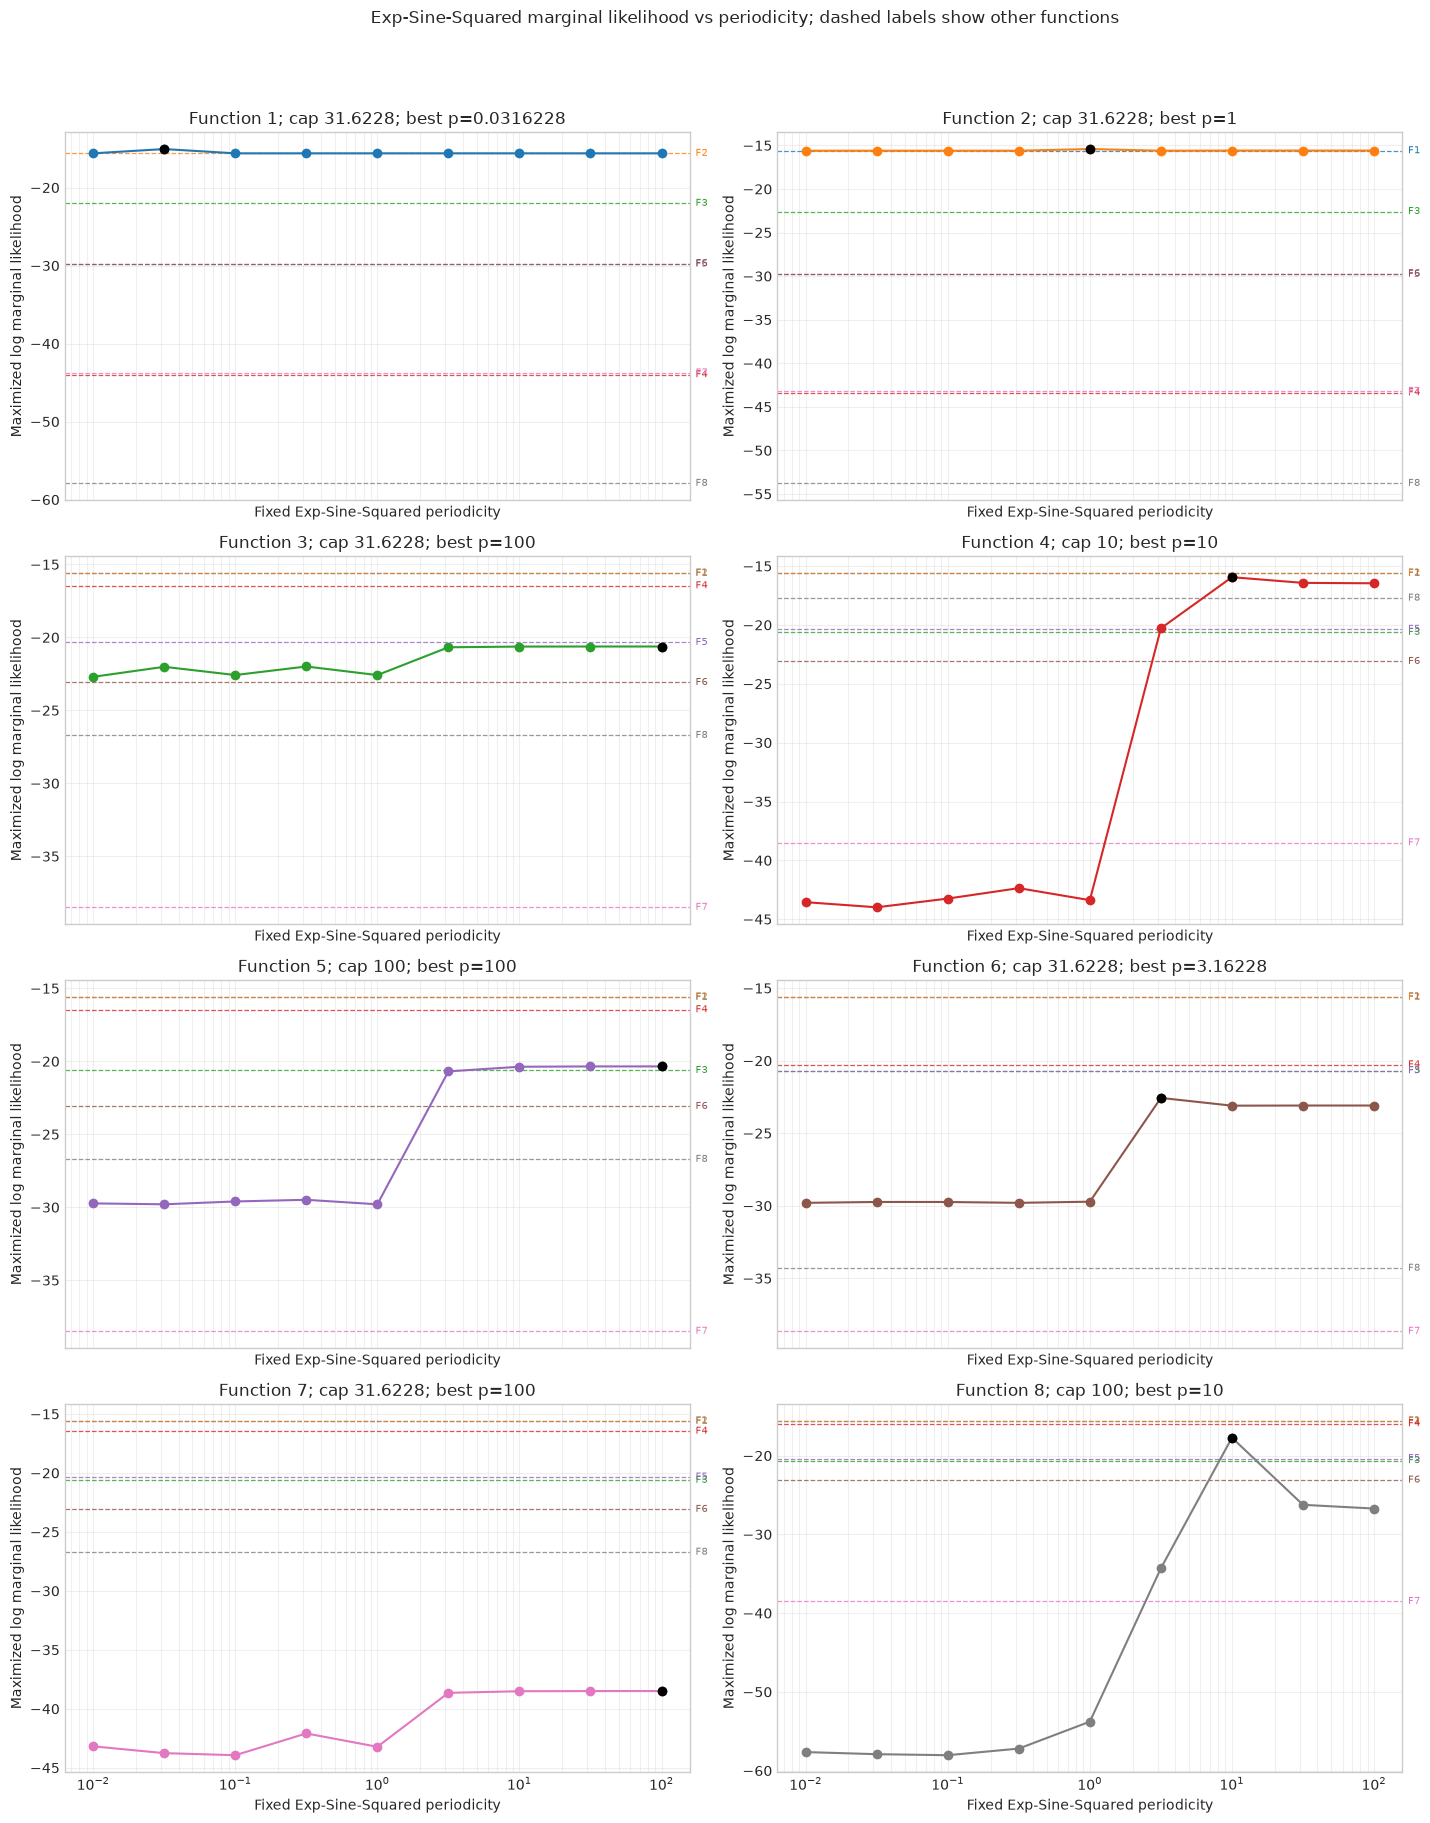

Maximized log marginal likelihood by function and fixed periodicity


periodicity,0.010000,0.031623,0.100000,0.316228,1.000000,3.162278,10.000000,31.622777,100.000000
function_id,,,,,,,,,
1,-15.608241,-15.059339,-15.608324,-15.608324,-15.608324,-15.608324,-15.608324,-15.608324,-15.608324
2,-15.608324,-15.608324,-15.608324,-15.607362,-15.417694,-15.608324,-15.589451,-15.589439,-15.589438
3,-22.703017,-22.017194,-22.581160,-21.995693,-22.584448,-20.679066,-20.630853,-20.626586,-20.626167
4,-43.551998,-43.987095,-43.246366,-42.359941,-43.381263,-20.286104,-15.945410,-16.427558,-16.463570
5,-29.735201,-29.797059,-29.603226,-29.488458,-29.797709,-20.689049,-20.372231,-20.350023,-20.347879
6,-29.797709,-29.737544,-29.739575,-29.797709,-29.718320,-22.566319,-23.100375,-23.091688,-23.090410
7,-43.182554,-43.758110,-43.933268,-42.087807,-43.220656,-38.647172,-38.509897,-38.497145,-38.495872
8,-57.644622,-57.913034,-58.040337,-57.200124,-53.780423,-34.302093,-17.721718,-26.246600,-26.718440


Best tested periodicity by function


,function_id,recommended_length_cap,periodicity,max_log_marginal_likelihood,convergence_warnings
0,1,31.622777,0.031623,-15.059339,0
1,2,31.622777,1.000000,-15.417694,0
2,3,31.622777,100.000000,-20.626167,0
3,4,10.000000,10.000000,-15.945410,1
4,5,100.000000,100.000000,-20.347879,0
5,6,31.622777,3.162278,-22.566319,0
6,7,31.622777,100.000000,-38.495872,0
7,8,100.000000,10.000000,-17.721718,1


In [ ]:
PERIODICITY_VALUES = np.logspace(-2, 2, 9)
periodicity_records = []

for function_id, observations in observations_by_function.items():
    length_cap = recommended_length_caps[function_id]
    for periodicity in PERIODICITY_VALUES:
        kernel = (
            ConstantKernel(1.0, (1e-3, 1e3))
            * ExpSineSquared(
                length_scale=1.0,
                periodicity=float(periodicity),
                length_scale_bounds=(1e-3, length_cap),
                periodicity_bounds="fixed",
            )
            + WhiteKernel(1e-5, (1e-8, 1e1))
        )
        model = GaussianProcessRegressor(
            kernel=kernel,
            normalize_y=CONFIG["normalize_y"],
            n_restarts_optimizer=CONFIG["n_restarts_optimizer"],
            random_state=CONFIG["random_state"],
        )
        with warnings.catch_warnings(record=True) as fit_warnings:
            warnings.simplefilter("always", ConvergenceWarning)
            model.fit(observations.inputs, observations.outputs)
        periodicity_records.append({
            "function_id": function_id,
            "periodicity": float(periodicity),
            "recommended_length_cap": length_cap,
            "max_log_marginal_likelihood": float(model.log_marginal_likelihood_value_),
            "convergence_warnings": sum(
                issubclass(warning.category, ConvergenceWarning)
                for warning in fit_warnings
            ),
        })

periodicity_sensitivity = pd.DataFrame(periodicity_records)

figure, axes = plt.subplots(4, 2, figsize=(15, 18), sharex=True, sharey=False)
axes = axes.ravel()
function_colors = plt.get_cmap("tab10")
for function_id, ax in zip(FUNCTION_IDS, axes):
    function_results = periodicity_sensitivity[
        periodicity_sensitivity["function_id"] == function_id
    ].sort_values("periodicity")
    best_result = function_results.loc[
        function_results["max_log_marginal_likelihood"].idxmax()
    ]
    reference_periodicity = float(best_result["periodicity"])
    likelihoods_at_reference_periodicity = periodicity_sensitivity[
        np.isclose(periodicity_sensitivity["periodicity"], reference_periodicity)
    ].set_index("function_id")["max_log_marginal_likelihood"]
    for comparison_function_id in FUNCTION_IDS:
        if comparison_function_id == function_id:
            continue
        reference_likelihood = likelihoods_at_reference_periodicity.loc[
            comparison_function_id
        ]
        reference_color = function_colors(comparison_function_id - 1)
        ax.axhline(
            reference_likelihood,
            color=reference_color,
            linestyle="--",
            linewidth=0.9,
            alpha=0.8,
            zorder=1,
        )
        ax.annotate(
            f"F{comparison_function_id}",
            xy=(1.0, reference_likelihood),
            xycoords=ax.get_yaxis_transform(),
            xytext=(4, 0),
            textcoords="offset points",
            color=reference_color,
            fontsize=7,
            va="center",
            clip_on=False,
        )
    ax.plot(
        function_results["periodicity"],
        function_results["max_log_marginal_likelihood"],
        marker="o",
        color=function_colors(function_id - 1),
        zorder=3,
    )
    ax.scatter(
        best_result["periodicity"],
        best_result["max_log_marginal_likelihood"],
        color="black",
        zorder=5,
    )
    ax.set_xscale("log")
    ax.set_title(
        f"Function {function_id}; cap {recommended_length_caps[function_id]:g}; "
        f"best p={reference_periodicity:g}"
    )
    ax.set_xlabel("Fixed Exp-Sine-Squared periodicity")
    ax.set_ylabel("Maximized log marginal likelihood")
    ax.grid(True, which="both", alpha=0.3)
figure.suptitle(
    "Exp-Sine-Squared marginal likelihood vs periodicity; dashed labels show other functions",
    y=1.01,
)
figure.tight_layout(rect=(0, 0, 0.96, 0.98))
plt.show()

likelihood_by_function_and_periodicity = periodicity_sensitivity.pivot(
    index="function_id",
    columns="periodicity",
    values="max_log_marginal_likelihood",
)
print("Maximized log marginal likelihood by function and fixed periodicity")
display(likelihood_by_function_and_periodicity)
print("Best tested periodicity by function")
display(
    periodicity_sensitivity.loc[
        periodicity_sensitivity.groupby("function_id")[
            "max_log_marginal_likelihood"
        ].idxmax(),
        [
            "function_id",
            "recommended_length_cap",
            "periodicity",
            "max_log_marginal_likelihood",
            "convergence_warnings",
        ],
    ].reset_index(drop=True)
)

In [ ]:
best_periodicity_by_function = periodicity_sensitivity.loc[
    periodicity_sensitivity.groupby("function_id")[
        "max_log_marginal_likelihood"
    ].idxmax(),
    ["function_id", "periodicity"],
].set_index("function_id")

cross_function_likelihood_rows = []
for reference_function_id, periodicity in best_periodicity_by_function["periodicity"].items():
    likelihoods_at_periodicity = periodicity_sensitivity[
        np.isclose(periodicity_sensitivity["periodicity"], periodicity)
    ].set_index("function_id")["max_log_marginal_likelihood"]
    cross_function_likelihood_rows.append({
        "reference_function_id": reference_function_id,
        "periodicity": periodicity,
        **{
            f"function_{function_id}": likelihoods_at_periodicity.loc[function_id]
            for function_id in FUNCTION_IDS
        },
    })

cross_function_likelihood_by_periodicity = pd.DataFrame(
    cross_function_likelihood_rows
).set_index(["reference_function_id", "periodicity"])
print("LML for every function at each function's best tested periodicity")
display(cross_function_likelihood_by_periodicity)

LML for every function at each function's best tested periodicity


,,function_1,function_2,function_3,function_4,function_5,function_6,function_7,function_8
reference_function_id,periodicity,,,,,,,,
1,0.031623,-15.059339,-15.608324,-22.017194,-43.987095,-29.797059,-29.737544,-43.758110,-57.913034
2,1.000000,-15.608324,-15.417694,-22.584448,-43.381263,-29.797709,-29.718320,-43.220656,-53.780423
3,100.000000,-15.608324,-15.589438,-20.626167,-16.463570,-20.347879,-23.090410,-38.495872,-26.718440
4,10.000000,-15.608324,-15.589451,-20.630853,-15.945410,-20.372231,-23.100375,-38.509897,-17.721718
5,100.000000,-15.608324,-15.589438,-20.626167,-16.463570,-20.347879,-23.090410,-38.495872,-26.718440
6,3.162278,-15.608324,-15.608324,-20.679066,-20.286104,-20.689049,-22.566319,-38.647172,-34.302093
7,100.000000,-15.608324,-15.589438,-20.626167,-16.463570,-20.347879,-23.090410,-38.495872,-26.718440
8,10.000000,-15.608324,-15.589451,-20.630853,-15.945410,-20.372231,-23.100375,-38.509897,-17.721718
